# Лабораторная работа № 2 — задача 5

**Объект:** 5 изделий, 8 процессов, 2 станка.

**Цель:** минимизировать момент завершения последнего выбранного процесса.

## Понимание задачи

Фабрика выпускает изделия разных типов.

Каждый процесс отвечает за один тип изделия и жёстко привязан к одному станку.

Процесс имеет постоянную производительность и минимально допустимое время запуска.

Процесс можно выбрать не более одного раза, если он выбран, без прерываний, а если не выбран то его длительность равна нулю.

У одного изделия могут быть несколько процессов-производителей. Их объёмы выпуска суммируются.

На каждом станке процессы выполняются последовательно. Между соседними процессами требуется переналадка, а перед первым процессом учитывается начальная переналадка.

Разные станки работа.т параллельно и не зависят друг от дурга, единственное что нас волнует суммарный выход (например 2 станка длают одну деталь)

Искомая величина — не сумма времени всех работ, а максимальный конец тиипа такого:

$$
C=\max_{p\in I:\,x_p=1}(S_p+t_p),
$$

Поэтому станки работают параллельно, а целевая функция минимизирует максимум двух временных линий.



In [63]:
%pip -q install ortools pandas matplotlib

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ortools.linear_solver import pywraplp
from google.colab import files

with open("input.txt", "r", encoding="utf-8-sig") as f:
    raw_text = f.read()

In [65]:
def parse_input(text):
    lines = [line.strip() for line in text.splitlines() if line.strip()]
    i = 0

    n_products = int(lines[i].split()[-1])
    i += 1
    products = lines[i:i + n_products]
    i += n_products

    i += 1
    demand = {products[j]: float(lines[i + j]) for j in range(n_products)}
    i += n_products

    n_machines = int(lines[i].split()[-1])
    i += 1
    machines = lines[i:i + n_machines]
    i += n_machines

    n_processes = int(lines[i].split()[-1])
    i += 1
    processes = lines[i:i + n_processes]
    i += n_processes

    i += 1
    proc_machine, proc_product = {}, {}
    min_amount, min_time = {}, {}

    for line in lines[i:i + n_processes]:
        p, m, s, amount, time = line.split()
        proc_machine[p] = m
        proc_product[p] = s
        min_amount[p] = float(amount)
        min_time[p] = float(time)
    i += n_processes

    i += 1
    setup = {}
    for line in lines[i:]:
        p, q, value = line.split()
        setup[p, q] = float(value)

    return (products, demand, machines, processes,
            proc_machine, proc_product, min_amount, min_time, setup)

(products, demand, machines, processes,
 proc_machine, proc_product, min_amount, min_time, setup) = parse_input(raw_text)

# Производные параметры модели.
procs_on = {m: [p for p in processes if proc_machine[p] == m] for m in machines}
producers = {s: [p for p in processes if proc_product[p] == s] for s in products}
rate = {p: min_amount[p] / min_time[p] for p in processes}
t_max = {p: demand[proc_product[p]] / rate[p] for p in processes}

assert all(min_time[p] <= t_max[p] for p in processes)
assert all(value >= 0 for value in setup.values())

print("Изделий:", len(products))
print("Станков:", len(machines))
print("Процессов:", len(processes))


Изделий: 5
Станков: 2
Процессов: 8


## Анализ исходных данных

Производительность процесса задаётся условием:
$$
r_p= \frac{\mathrm{MinAmount}_p}{\mathrm{MinTime}_p}
$$
Для процесса `p`, производящего изделие `s_p`, используем верхнюю границу
$$
T_p^{\max}=\frac{D_{s_p}}{r_p}.
$$

Далее мы покажем почемы длительность одного процесса сверх $D_{s_p}/r_p$ можно сократить не нарушая спрос и не увеличив `max C`.

Изделия `s1`, `s2`, `s3` имеют по одному производителю — соответственно `t1`, `t2`, `t3`. Поэтому эти процессы обязательны.
иначе бы эта наша штука занулилась и мы бы не смогли решить задачу
$$
t_p≤T_p^{max}x_p
$$ ну то есть однозначно

Изделие `s4` могут производить `t4`, `t6`, `t8`; изделие `s5` — `t5`, `t7`.


In [66]:
rows = []
for p in processes:
    rows.append({
        "Процесс": p,
        "Станок": proc_machine[p],
        "Изделие": proc_product[p],
        "MinAmount": min_amount[p],
        "Tmin, ч": min_time[p],
        "Производительность r, ед/ч": rate[p],
        "Tmax = D/r, ч": t_max[p],
    })
process_table = pd.DataFrame(rows)
display(process_table.round(5))

print("\nСтруктура производителей:")
display(pd.DataFrame([
    {"Изделие": s, "Спрос": demand[s], "Возможные процессы": ", ".join(producers[s]),
     "Число процессов": len(producers[s])}
    for s in products
]))

mandatory = {ps[0] for s, ps in producers.items() if len(ps) == 1}
print("Обязательные процессы (единственный производитель изделия):", sorted(mandatory))

,Процесс,Станок,Изделие,MinAmount,"Tmin, ч","Производительность r, ед/ч","Tmax = D/r, ч"
0,t1,u1,s1,34.60820,11.34364,3.05089,104.48489
1,t2,u2,s2,75.42740,18.47434,4.08282,74.86725
2,t3,u2,s3,86.04224,17.63775,4.87830,95.76144
3,t4,u1,s4,47.22084,12.55069,3.76241,102.74091
4,t5,u1,s5,51.34127,14.95435,3.43320,131.78842
5,t6,u2,s4,64.52714,14.49491,4.45171,86.83257
6,t7,u1,s5,56.87062,16.51593,3.44338,131.39881
7,t8,u1,s4,87.25981,17.88723,4.87833,79.23888



Структура производителей:


,Изделие,Спрос,Возможные процессы,Число процессов
0,s1,318.77192,t1,1
1,s2,305.66950,t2,1
2,s3,467.15302,t3,1
3,s4,386.55341,"t4, t6, t8",3
4,s5,452.45602,"t5, t7",2


Обязательные процессы (единственный производитель изделия): ['t1', 't2', 't3']


граница времени работы станка для станка `m`
$$
H_m=\sum_{p\in I_m}T_p^{\max}+\sum_{p,q\in I_m}a_{pq}.
$$
В любой последовательности используются только некоторые положиельные длительности процессов и только одна начальная положиельная переналадка с переходами между соседними процессами.

Существует оптимальное, укладывающееся в `H_m`.

Общая граница коенчная граница сверху равна $H=max(H_m)$, поскольку станки работают параллельно.


In [67]:
H_machine = {}
for m in machines:
    pm = procs_on[m]
    process_part = sum(t_max[p] for p in pm)
    setup_part = sum(setup[(p, q)] for p in pm for q in pm)
    H_machine[m] = process_part + setup_part
H = max(H_machine.values())

print("Границы H_m:")
for m in machines:
    print(f"  {m}: {H_machine[m]:.6f} ч")
print(f"Общая граница H = max(H_m): {H:.6f} ч")
print(f"Максимальная переналадка: {max(setup.values()):.5f} ч")

Границы H_m:
  u1: 3063.015662 ч
  u2: 1126.529114 ч
Общая граница H = max(H_m): 3063.015662 ч
Максимальная переналадка: 194.69028 ч


## Математическая модель

### Множества и параметры

- `S` — изделия; `I` — процессы; `U` — станки.
- `I_m={p∈I : m_p=m}` — процессы на станке `m`.
- `D_s` — спрос изделия `s`.
- `s_p`, `m_p` — изделие и станок процесса `p`.
- `r_p>0` — производительность; `T_p^min` — минимальное время процесса.
- `a_pq≥0` — переналадка с `p` на `q`; `a_pp` — начальная переналадка, если `p` первый.



### Переменные

| Переменная | Тип | Смысл |
|---|---|---|
| `x_p` | булева | выбран ли процесс `p` |
| `t_p` | непрерывная | длительность процесса |
| `S_p` | непрерывная | начало обработки после переналадки |
| `f_p` | булева | является ли `p` первым на станке |
| `z_pq` | булва | следует ли `q` непосредственно за `p`важно что именно за, это ребро пара ну тупа|
| `C` | непрерывная | момент завершения последнего процесса грубо говоря макс длительность среди станков|

### Целевая функция

$$
{\min C}
$$

### Ограничения

**(1) Выполнение спроса:**
Для начала поймем сколько надо чтобы закрыть спрос, тут по аналогии со скоростью и временем просто находим итог множением скорости на время
$$
\sum_{p:\,s_p=s}r_pt_p\ge D_s,\qquad s\in S.
$$

Перепроизводство разрешено, поэтому стоит `≥`.



**(2) Связь выбора и длительности:**
$$
T_p^{\min}x_p\le t_p\le T_p^{\max}x_p,\qquad p\in I.
$$
Если процесс не выбран (`x_p=0`), его длительность равна нулю.

Если выбран, он работает не меньше `Tmin`
тмин мы по условию берем, тмакс это просто когда мы закроем запрос

$$
T_p^{\max}=\frac{D_{s_p}}{r_p}.
$$


**(3) задаем цпочку на станке:**

Каждый выбранный процесс имеет ровно одного предшественника или является первым.
$$
f_p+\sum_{q\in I_m,\,q != p}z_{qp}=x_p,\qquad p\in I_m,
$$

у него не более одного непосредственного преемника.
$$
\sum_{q\in I_m,\,q != p}z_{pq}\le x_p,\qquad p\in I_m,
$$

Если хотя бы один процесс выбран, первый процесс ровно один.
$$
\sum_{p\in I_m}f_p\le1,\qquad
$$
Но пока это не дает гарантии, что первый процесс вообще говоря существует, тк эта штука выполянется и без него, когда выбран процесс((
Докинем
$$
\sum_{p\in I_m}f_p\ge x_q,\quad \forall q\in I_m.
$$


**(4) Начальная переналадка и переналадки между соседними процессами:**
$$
S_p\ge a_{pp}f_p,
$$

$$
S_q\ge S_p+t_p+a_{pq}-M_{pq}(1-z_{pq}),\qquad p!=q,
$$
где $M_{pq}=H_m+a_{pq}$ для процессов одного станка.

**(5) Временные границы:**
$$
S_p+t_p\le H_mx_p,\qquad p\in I_m,
$$

$$
0\le C\le H,\qquad C\ge S_p+t_p,\quad p\in I.
$$

на самом деле неравенство для c это упрощение, там можно брать макс, но неравенство линейное и удобное - так сказала нейронка, в целом разницы для нас нет что там будет стоять

Поскольку `S_p,t_p≥0`, первое ограничение автоматически даёт `S_p=0` для невыбранного процесса. Отдельная верхняя граница на `S_p` не нужна.

Все ограничения линейны. Бинарные переменные делают задачу смешанно-целочисленной линейной.


## Замечание 1 про Tmax

Поговорим про Tmax

мы утверждаем, что для каждого процесса `p` существует оптимальное решение, в котором

$$
t_p\le T_p^{\max}=D_{s_p}/r_p.
$$

Покажеми это

Пусть в некотором допустимом расписании выбран процесс `p` и
$$
t_p>T_p^{max}
$$
Тогда только процесс `p` выпускает
$$
r_pt_p>D_{s_p}.
$$

Получается, только этот процесс уже производит больше, чем весь требуемый спрос на соответствующее изделие.

Значит, мы можем сократить его длительность до:
$$
t_p'=T_p^{max}
$$

После сокращения:
$$
r_pt_p'=D_{s_p}
$$

То есть только этот процесс уже способен выполнить весь спрос.

Cуммарный выпуск всё равно будет не меньше спроса, как минимум другие процессы того же изделия также могут что-то производить.

Теперь посмотрим на влияние на расписание.

Если процесс p стал короче, следовательно, переналадка и начало следующего процесса могут остаться на прежних местах или произойти раньше.

Расписание не станет хуже.

### Замечание 2 Hm

Пусть наши станки не простаивают, они всегда либо в наладке либо работают

Для каждого станка `m` определяли такую величину

$$
H_m=\sum_{p\in I_m}T_p^{\max}+\sum_{p,q\in I_m}a_{pq}.
$$

Тогда существует оптимальное расписание, в котором конец любого выбранного процесса на `m` не превосходит `H_m`, а время остановки последнего станка не превосходит $H=\max_mH_m$.

**Доказательство.** Рассмотрим любую фиксированную последовательность выбранных процессов на станке:
`p1 → p2 → ... → pk`. Длительность такого компактного расписания равна
$$
a_{p_1p_1}+\sum_{i=1}^{k}t_{p_i}+\sum_{i=1}^{k-1}a_{p_ip_{i+1}}.
$$
Ранее мы показали, что каждое `t_p≤Tmax_p`. Все слагаемые неотрицательны, а реально использованные переналадки являются подмножеством всех пар `(p,q)` на станке. Поэтому выражение не превосходит `H_m`. Это верно для каждого станка независимо.

Важно: `H_m` ограничивает **компактное расписание без лишнего простоя**, в котором можно искать оптимум. Не утверждается, что произвольно задержанное расписание тоже обязано укладываться в `H_m`.

### Замечание 3 M_pq

В нашей модели:
$$ M_{pq}=H_m+a_{pq} $$
Временное ограничение:
$$ S_q\geq S_p+t_p+a_{pq}-M_{pq}(1-z_{pq}) $$
Мы хотим доказать, что когда $(z_{pq}=0)$, оно не накладывает лишних условий.

Подставим:
$$ z_{pq}=0 $$
Получаем:
$$ S_q\geq S_p+t_p+a_{pq}-M_{pq} $$
Подставим формулу M:
$$ S_q\geq S_p+t_p+a_{pq}-(H_m+a_{pq}) $$
Сократим переналадку:
$$ S_q\geq S_p+t_p-H_m $$
Но из предыдущего ограничения:
$$ S_p+t_p\leq H_m $$
Следовательно:
$$ S_p+t_p-H_m\leq0 $$
А мы также знаем:
$$ S_q\geq0 $$
Получается:
$$ S_q\geq S_p+t_p-H_m $$
автоматически выполняется.


###  Существование оптимума

После введения границ `0≤t_p≤Tmax_p`, `0≤S_p≤H_m` и `0≤C≤H` все непрерывные переменные ограничены; бинарных комбинаций конечное число. Целевая функция `C` непрерывна, поэтому мы найдем оптимум

## Реализация

In [68]:
def build_model(forbidden=(), show_output=False):
    solver = pywraplp.Solver.CreateSolver("SCIP")
    if show_output:
        solver.EnableOutput()

    x = {p: solver.BoolVar("x_" + p) for p in processes}
    f = {p: solver.BoolVar("f_" + p) for p in processes}
    t = {p: solver.NumVar(0, t_max[p], "t_" + p) for p in processes}
    S = {p: solver.NumVar(0, H_machine[proc_machine[p]], "S_" + p) for p in processes}
    C = solver.NumVar(0, H, "C")

    z = {}
    for m in machines:
        for p in procs_on[m]:
            for q in procs_on[m]:
                if p != q:
                    z[p, q] = solver.BoolVar("z_" + p + "_" + q)

    # 1 Выпуск каждого изделия не меньше спроса.
    for s in products:
        solver.Add(sum(rate[p] * t[p] for p in producers[s]) >= demand[s])

    # 2 Выбор процесса и его длительность.
    for p in processes:
        solver.Add(t[p] >= min_time[p] * x[p])
        solver.Add(t[p] <= t_max[p] * x[p])
        solver.Add(S[p] + t[p] <= H_machine[proc_machine[p]] * x[p])

    # 3 Выбранные процессы на станке образуют одну цепочку.
    for m in machines:
        pm = procs_on[m]
        first_count = sum(f[p] for p in pm)
        solver.Add(first_count <= 1)

        for p in pm:
            incoming = sum(z[q, p] for q in pm if q != p)
            outgoing = sum(z[p, q] for q in pm if q != p)
            solver.Add(f[p] + incoming == x[p])
            solver.Add(outgoing <= x[p])
            solver.Add(first_count >= x[p])

    # 4 Начальные и межпроцессные переналадки.
    for m in machines:
        pm = procs_on[m]
        for p in pm:
            solver.Add(S[p] >= setup[p, p] * f[p])
            for q in pm:
                if p != q:
                    M = H_machine[m] + setup[p, q]
                    solver.Add(S[q] >= S[p] + t[p] + setup[p, q] - M * (1 - z[p, q]))

    # 5 Makespan.
    for p in processes:
        solver.Add(C >= S[p] + t[p])


    solver.Minimize(C)
    return solver, x, t, S, C, f, z

solver, x, t, S, C, f, z = build_model(show_output=True)
print("Переменных:", solver.NumVariables())
print("Ограничений:", solver.NumConstraints())


Переменных: 59
Ограничений: 97


## Решение задачи


In [69]:
status = solver.Solve()

if status != pywraplp.Solver.OPTIMAL:
    raise RuntimeError("Решатель не доказал оптимальность. Статус: " + str(status))

C_star = C.solution_value()
solution = {
    "x": {p: x[p].solution_value() for p in processes},
    "t": {p: t[p].solution_value() for p in processes},
    "S": {p: S[p].solution_value() for p in processes},
    "f": {p: f[p].solution_value() for p in processes},
    "z": {pq: z[pq].solution_value() for pq in z},
}

print(C_star)


416.53494600335193


## 8. Восстановление расписания

По переменным `f` и `z` восстанавливаем порядок процессов на каждом станке. Затем ставим каждый процесс как можно раньше: первый — после начальной переналадки, следующий — после завершения предыдущего и переналадки между ними.


In [70]:
sequences = {}

for m in machines:
    chosen = [p for p in procs_on[m] if solution["x"][p] > 0.5]
    sequence = []

    if chosen:
        current = next(p for p in chosen if solution["f"][p] > 0.5)
        while current is not None:
            sequence.append(current)
            next_process = [q for q in chosen if q != current and solution["z"].get((current, q), 0) > 0.5]
            current = next_process[0] if next_process else None

    assert len(sequence) == len(chosen)
    sequences[m] = sequence

schedule = {}
for m in machines:
    for k, p in enumerate(sequences[m]):
        if k == 0:
            setup_start = 0
            setup_duration = setup[p, p]
        else:
            previous = sequences[m][k - 1]
            setup_start = schedule[previous]["end"]
            setup_duration = setup[previous, p]

        start = setup_start + setup_duration
        end = start + solution["t"][p]
        schedule[p] = {
            "setup_start": setup_start,
            "setup_duration": setup_duration,
            "start": start,
            "duration": solution["t"][p],
            "end": end,
        }

C_rebuilt = max(row["end"] for row in schedule.values())

for m in machines:
    print(m, ":", " -> ".join(sequences[m]))
print(f"Время завершения расписания: {C_rebuilt:.6f} ч")


u1 : t1 -> t5 -> t4
u2 : t2 -> t6 -> t3
Время завершения расписания: 416.534946 ч


## 10. Диаграмма Ганта

Серые штрихованные блоки — начальные переналадки и переходы между процессами. Цветные блоки — обработка. На каждой горизонтальной линии показан отдельный станок. Переналадка перед первым процессом отсчитывается от времени 0; переналадка между процессами начинается после завершения предыдущего процесса.

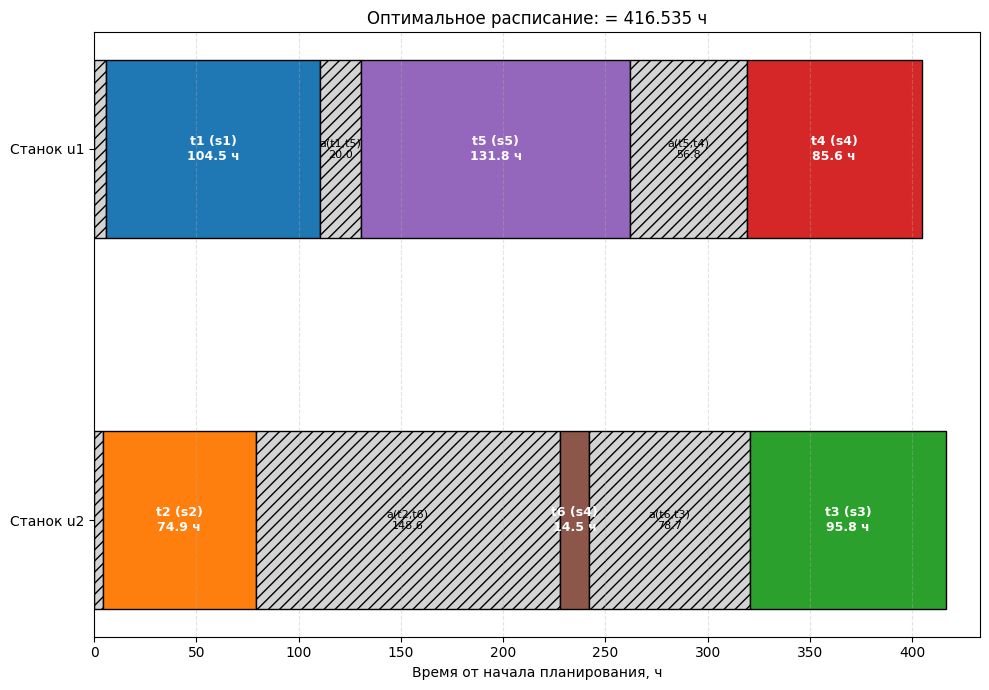

In [71]:
colors = {
    "t1": "#1f77b4", "t2": "#ff7f0e", "t3": "#2ca02c", "t4": "#d62728",
    "t5": "#9467bd", "t6": "#8c564b", "t7": "#e377c2", "t8": "#7f7f7f",
}
fig, ax = plt.subplots(figsize=(10, 7))

for y, m in enumerate(machines):
    for k, p in enumerate(sequences[m]):
        row = schedule[p]
        # Блок переналадки.
        ax.barh(y, row["setup_duration"], left=row["setup_start"],
                color="lightgray", edgecolor="black", hatch="///", height=0.48)
        if row["setup_duration"] >= 8:
            setup_label = "INIT" if k == 0 else f"a({sequences[m][k-1]},{p})"
            ax.text(row["setup_start"] + row["setup_duration"]/2, y,
                    f"{setup_label}\n{row['setup_duration']:.1f}",
                    ha="center", va="center", fontsize=8)
        # Блок процесса.
        ax.barh(y, row["duration"], left=row["start"], color=colors.get(p, "gray"),
                edgecolor="black", height=0.48)
        ax.text(row["start"] + row["duration"]/2, y,
                f"{p} ({proc_product[p]})\n{row['duration']:.1f} ч",
                ha="center", va="center", color="white", fontsize=9, fontweight="bold")

ax.set_yticks(range(len(machines)))
ax.set_yticklabels([f"Станок {m}" for m in machines])
ax.set_xlabel("Время от начала планирования, ч")
ax.set_title(f"Оптимальное расписание: = {C_star:.3f} ч")
ax.set_xlim(0, C_star * 1.04)
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.invert_yaxis()
plt.tight_layout()
plt.show()